#  تحلیل احساس نظرات فارسی با فاین‌تیون ParsBERT
دیتاست: mteb/SentimentDKSF (نظرات دیجی‌کالا و اسنپ‌فود). مدل پایه: HooshvareLab/bert-fa-base-uncased. مقایسه با baseline TF-IDF + Logistic Regression.

In [1]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
# %pip install -q -r requirements.txt

## ۱. بارگذاری داده، EDA و نرمال‌سازی


In [2]:
import re
from datasets import load_dataset
from sklearn.model_selection import train_test_split

ds = load_dataset("mteb/SentimentDKSF")
train_df, test_df = ds["train"].to_pandas(), ds["test"].to_pandas()
print(train_df.head())
print(train_df["label"].value_counts(normalize=True).round(3))
print(test_df["label"].value_counts(normalize=True).round(3))
print(train_df["text"].str.split().str.len().describe().round(1))

NUM = train_df["label"].nunique()
assert sorted(train_df["label"].unique()) == list(range(NUM)), "labels are not 0..K-1"

DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "01234567890123456789")
def normalize(t):
    t = t.replace("ي", "ی").replace("ك", "ک").replace("ة", "ه")
    t = re.sub(r"[\u064B-\u065F\u0640]", "", t)      # اعراب و کشیده
    t = t.translate(DIGITS)                              # یکسان‌سازی ارقام
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)              # حروف تکراری
    return re.sub(r"\s+", " ", t).strip()

for d in (train_df, test_df):
    d["text"] = d["text"].map(normalize)
tr_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df["label"], random_state=42)
print(len(tr_df), len(val_df), len(test_df))

                                                text  label
0                         شیشه هاش همون روز اول شکست      0
1  تمیز -مرتب- چقدر پیک آن تایم و مؤدب …سپاس بسیا...      1
2  نظر من هیچ گاه این محصول رو خریداری نکنید اگه ...      0
3  برنج ایرانی سفارش دادم افتضاح بود با هندی هیچ ...      0
4         سلام اصلا راضی نیستم  یعنی ارزش خرید نداره      0
label
0    0.357
1    0.335
2    0.308
Name: proportion, dtype: float64
label
0    0.478
1    0.446
2    0.076
Name: proportion, dtype: float64
count    28602.0
mean        25.8
std         31.3
min          1.0
25%          9.0
50%         17.0
75%         32.0
max        586.0
Name: text, dtype: float64
25741 2861 2315


In [3]:
# نمونه‌هایی از هر برچسب برای فهمیدن معنی آن‌ها
for l in range(NUM):
    print("label", l)
    for t in train_df[train_df.label == l]["text"].sample(6, random_state=1):
        print("  -", t[:110])

label 0
  - یه کم احترام به مشتری یعنی اینکه حداقل غذا به موقع برسه که متاسفانه این هم حتی وجود نداشت. دفعات قبلی بد نبود 
  - علیرغم تقاضای خود را هنگام سفارش مبنی بر عدم روی هم گذاشتن کباب و برنج، بی توجه این کار را تکرار کرد
  - اصلا توضیحات رو نمیخونن و هردفعه هر چی نوشتم اصلا انگار نه انگار. نوشتم جوجه مغز پخت شه چون میدونستم یه کم زود
  - اصلا خوب نیست جلوی کسی خجالت میکشی ترمز کنی از بس سوت میکشه
  - داخل توضیحات گفته شد که ساندویچ بدون گوجه باشه ولی متاسفانه توجه نشد و به خاطر مجبورشدم بریزم دور
  - طرحش قشنگه ولی کمی سنگینه وظریف نیست
label 1
  - عمر مفید و کاربری بالا
  - بی نهایت خوب و عالی و بسیار سریع جذب موها میشه . اصلا گاز بدبو و اذیت کننده نداشت.
  - غذاها خوب بود ولی دقیقا یکساعت طول کشید تا بدستمون برسه
  - با توجه به قیمت و ویژگی های آن، محصول مناسبی برای خرید است.
  - بجای نان تست طلایی برای من نان تست سبوس دار فرستادن
  - نسبت به بی ارزش بودن در حال حاضر ریال ایران بهترین گزینه است در این مقطع قیمتی
label 2
  - درود، جناب رشید پور تو رو خداا حالا که تووی برف هستید

## ۲. Baseline: TF-IDF + Logistic Regression


In [4]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(tr_df["text"])
lr = LogisticRegression(max_iter=1000, C=3).fit(Xtr, tr_df["label"])
pred_b = lr.predict(vec.transform(test_df["text"]))

base_acc = accuracy_score(test_df["label"], pred_b)
base_f1 = f1_score(test_df["label"], pred_b, average="macro")
print(f"Baseline  acc={base_acc:.4f}  macro-F1={base_f1:.4f}")
print(classification_report(test_df["label"], pred_b, digits=3))
print(confusion_matrix(test_df["label"], pred_b))
print(pd.Series(pred_b).value_counts().sort_index())

Baseline  acc=0.8432  macro-F1=0.7818
              precision    recall  f1-score   support

           0      0.885     0.879     0.882      1107
           1      0.931     0.802     0.862      1032
           2      0.463     0.858     0.602       176

    accuracy                          0.843      2315
   macro avg      0.760     0.846     0.782      2315
weighted avg      0.873     0.843     0.852      2315

[[973  50  84]
 [113 828  91]
 [ 14  11 151]]
0    1100
1     889
2     326
Name: count, dtype: int64


## ۳. فاین‌تیون ParsBERT
`SUBSET` تعداد نمونه‌های آموزشی را تعیین می‌کند (`None` یعنی کل داده). برای اجرای کامل روی CPU زمان زیادی لازم است؛ GPU توصیه می‌شود.

In [5]:
import math, numpy as np, torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

print("GPU:", torch.cuda.is_available())
MODEL = "HooshvareLab/bert-fa-base-uncased"
SUBSET = 2000                  # None = کل داده
OUT_DIR = "out_sentiment" if SUBSET else "out_sentiment_full"
tok = AutoTokenizer.from_pretrained(MODEL)

def prep(df, n=None):
    if n: df = df.sample(n=min(n, len(df)), random_state=42)
    d = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return d.map(lambda b: tok(b["text"], truncation=True, max_length=128),
                 batched=True, remove_columns=["text"])

tr, va, te = prep(tr_df, SUBSET), prep(val_df), prep(test_df)

def metrics(p):
    pr = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pr),
            "f1": f1_score(p.label_ids, pr, average="macro")}

BATCH, EPOCHS = 32, 3
warmup = int(0.1 * math.ceil(len(tr) / BATCH) * EPOCHS)

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=NUM)
args = TrainingArguments(
    output_dir=OUT_DIR, num_train_epochs=EPOCHS, learning_rate=2e-5,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=64,
    weight_decay=0.01, warmup_steps=warmup,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1",
    fp16=torch.cuda.is_available(), report_to="none", seed=42)

trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=va,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
trainer.train()

GPU: False


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2861 [00:00<?, ? examples/s]

Map:   0%|          | 0/2315 [00:00<?, ? examples/s]

[transformers] BertForSequenceClassification LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	thos

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.707808,0.698357,0.692232
2,No log,0.650826,0.727368,0.725128
3,No log,0.659644,0.732961,0.730059


TrainOutput(global_step=189, training_loss=0.6362042300915592, metrics={'train_runtime': 354.4244, 'train_samples_per_second': 16.929, 'train_steps_per_second': 0.533, 'total_flos': 336045168204480.0, 'train_loss': 0.6362042300915592, 'epoch': 3.0})

## ۴. ارزیابی روی تست و تحلیل خطا


ParsBERT  acc=0.7827  macro-F1=0.6864   (baseline: 0.8432 / 0.7818)
              precision    recall  f1-score   support

           0      0.836     0.836     0.836      1107
           1      0.891     0.762     0.821      1032
           2      0.310     0.574     0.402       176

    accuracy                          0.783      2315
   macro avg      0.679     0.724     0.686      2315
weighted avg      0.820     0.783     0.796      2315



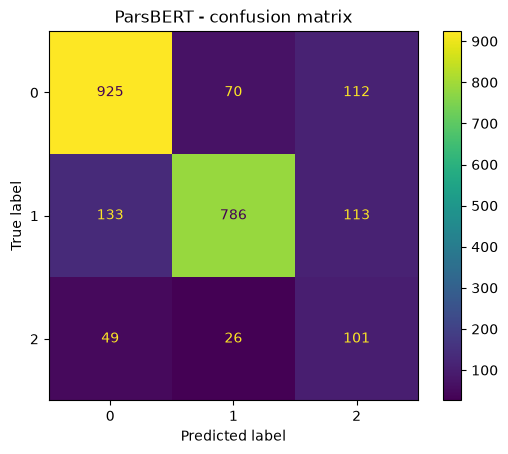

errors: 503
[gold=1 pred=2] من دوسش دارم
[gold=0 pred=2] این ترازو هر چند از نظر استحکام خوب است.ولی یکی دو کیلو اختلاف وزن را نشان میدهد البته بیشتر در دفعه اول این اتفاق می افتد.ضمنا کار با این ترازو یکی س
[gold=0 pred=2] فقط طراحی عطر زیبا به نظر میرسد و رایحه به هیج وجه به نمونه اصلی نزدیک نیست اما با توجه به قیمت برای خرید توصیه میشود.
[gold=1 pred=2] کیفیت ساختش خیلی بالاستخیلی شیک و خوش سایزهحتی توی جیبم جا میشهاویزش خیلی به درد بخورهمگنتش قویهدوتا ضعف دارهیکی نداشتن منبع تغذیه قابل شارژ ، که ایکا
[gold=0 pred=2] دکمه هاش گیر میکنه
[gold=1 pred=2] کامپیوتر فوق العاده ایهمن زمانی گرفتمش که قیمت ها خیلی بالا نرفته بود و واقعن یکی از بهترین خریدهای من بود.صداش خیلی کمه، سرعت پردازنده و رم عالیحتی گ
[gold=2 pred=1] ابعاد اصلی محصول 12×12 استو کوچک میباشداما کتاب زیبا و جذابیست برای نوزادان
[gold=1 pred=0] متاسفانه کمى سرد شده بود مگرنه مثل همیشه عالى بود ولى سیبزمینى هاى قدیم بهتر بودند
[gold=1 pred=0] متاسفانه ویفر رو اشتباهی یه چیز دیگه فرستادن. ممنون میشم بیشتر دقت کنید
[gold=1 p

In [6]:
import matplotlib.pyplot as plt, json
from sklearn.metrics import ConfusionMatrixDisplay

out = trainer.predict(te)
pred = out.predictions.argmax(-1)
acc = accuracy_score(test_df["label"], pred)
f1 = f1_score(test_df["label"], pred, average="macro")
print(f"ParsBERT  acc={acc:.4f}  macro-F1={f1:.4f}   (baseline: {base_acc:.4f} / {base_f1:.4f})")
print(classification_report(test_df["label"], pred, digits=3))

ConfusionMatrixDisplay.from_predictions(test_df["label"], pred)
plt.title("ParsBERT - confusion matrix"); plt.savefig("cm_sentiment.png", dpi=150); plt.show()

err = test_df.assign(pred=pred)
err = err[err["label"] != err["pred"]]
print("errors:", len(err))
for _, r in err.sample(min(10, len(err)), random_state=1).iterrows():
    print(f"[gold={r['label']} pred={r['pred']}]", r["text"][:150])

json.dump({"baseline_acc": base_acc, "baseline_f1": base_f1, "bert_acc": acc, "bert_f1": f1,
           "train_subset": SUBSET}, open("results_sentiment.json", "w"), indent=1)

## ۵. ذخیره مدل و نمونه استفاده

In [7]:
trainer.save_model("model_sentiment"); tok.save_pretrained("model_sentiment")

from transformers import pipeline
pipe = pipeline("text-classification", model="model_sentiment", device=0 if torch.cuda.is_available() else -1)
print(pipe(["کیفیت عالی بود، ممنون", "بعد از دو روز خراب شد"]))

[{'label': 'LABEL_1', 'score': 0.971738874912262}, {'label': 'LABEL_0', 'score': 0.8743065595626831}]
